# Sensibilité à une formation supplémentaire

Slide 10. Le dictionnaire (slide 16) décrit le nombre de formations terminées l’année précédente. En sensibilité, les personnes à zéro formation passent à une. Le fichier ne repère ni les métiers critiques, ni le contenu ou la participation au programme, ni les entretiens de fidélisation. Le passage de zéro à une formation est un scénario hypothétique sur une composante du plan de carrière. La formation des managers à la planification (slide 35) demanderait en plus d’identifier les managers concernés et leurs équipes.

## 1. Reconstituer la régression logistique finale

Le pipeline final est réajusté sur le split archivé de 1 214 salariés, dans son ordre d’origine. Les métriques calculées à partir des scores initiaux sont comparées à toutes les lignes du test final archivé avant de modifier les données. Le pipeline final réencode ou standardise les entrées utilisées et ne contient aucune variable dérivée de ces leviers.

In [1]:
from IPython.display import display

from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

racine = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src/modeling.py').is_file())
sys.path.insert(0, str(racine))

from src.final_analysis import metrics
from src.modeling import build_pipelines, load_model_data, make_split

archives = racine / 'reports/tables/final'
config = json.loads((archives / 'model.json').read_text(encoding='utf-8'))
assert config['model'] == 'Logistique' and config['variant'] == 'pruned'
validation = pd.read_csv(archives / 'validation.csv', float_precision='round_trip')
reference = pd.read_csv(archives / 'test.csv', float_precision='round_trip').set_index('rule')
ligne_seuil = validation.loc[
    validation.model.eq(config['model'])
    & validation.variant.eq(config['variant'])
    & validation.rule.eq('Max OOF F2')
]
assert len(ligne_seuil) == 1
seuil = float(ligne_seuil.threshold.iloc[0])
assert seuil == reference.loc['Max OOF F2', 'threshold'] == 0.1524622157832296

donnees, cible, lignes_source, _, quantitatives = load_model_data()
X_train, X_test, y_train, y_test, _, split = make_split(donnees, cible, lignes_source, n_splits=4)
split_archive = pd.read_csv(archives / 'split.csv', dtype={'pli_validation': 'Int64'})
pd.testing.assert_frame_equal(split, split_archive)
historique = pd.read_csv(racine / 'outputs/models/04_indices_split_plis.csv')
pd.testing.assert_frame_equal(split.drop(columns='pli_validation'), historique.drop(columns='pli_validation'))
assert (len(X_test), int(y_test.sum())) == (304, 50)
pd.testing.assert_index_equal(X_test.index, y_test.index)

pipeline = build_pipelines(quantitatives, excluded=config['candidate_exclusions'])[config['model']]
pipeline.set_params(**config['parameters']).fit(X_train, y_train)
classe_depart = int(np.flatnonzero(pipeline.classes_ == 1).item())
score_avant = pd.Series(pipeline.predict_proba(X_test)[:, classe_depart], index=X_test.index)
prediction_avant = score_avant >= seuil
rejoue = pd.DataFrame.from_dict(
    {regle: metrics(y_test, score_avant, ligne.threshold) for regle, ligne in reference.iterrows()},
    orient='index',
)
pd.testing.assert_frame_equal(rejoue, reference, check_names=False, atol=1e-12, rtol=0)
print(f'Seuil exact Max OOF F2 : {seuil!r}')
display(rejoue)
assert X_test.index.is_unique
ordre_test = split_archive.loc[split_archive.partie.eq('test')].sort_values('ordre_dans_partie')
np.testing.assert_array_equal(X_test.index.to_numpy(), ordre_test.position_dataset.to_numpy())
np.testing.assert_array_equal(lignes_source.loc[X_test.index], ordre_test.ligne_excel_source)


Seuil exact Max OOF F2 : 0.1524622157832296


,threshold,precision,recall,f2,ap,auc,tn,fp,fn,tp
Max OOF F2,0.152462,0.373832,0.80,0.651466,0.683905,0.86874,187,67,10,40
0.50,0.500000,0.800000,0.32,0.363636,0.683905,0.86874,250,4,34,16


## 2. Simuler sur les données source du test

Les modalités affichées proviennent de la base de référence et du test. La cible historique reste à part.

In [2]:
variable = 'TrainingTimesLastYear'
transition = {0: 1}
libelle = 'où les salariés sans formation en suivent une'

# Populations et transitions définies uniquement à partir des entrées d’origine.
display(pd.concat({
    'Base': donnees[variable].value_counts().sort_index(),
    'Test': X_test[variable].value_counts().sort_index(),
}, axis=1).fillna(0).astype(int))

categories = pipeline.named_steps['preparation']
if variable == 'OverTime':
    assert set(donnees[variable].unique()) == {'Yes', 'No'}
elif variable == 'TrainingTimesLastYear':
    assert set(transition.values()).issubset(donnees[variable].unique())
    assert variable in categories.named_transformers_['quantitatives'].feature_names_in_
else:
    encodeur = categories.named_transformers_['categories_scores']
    position = list(encodeur.feature_names_in_).index(variable)
    assert set(transition.values()).issubset(encodeur.categories_[position])

eligibles = X_test[variable].isin(transition)
scenario = X_test.copy(deep=True)
scenario.loc[eligibles, variable] = X_test.loc[eligibles, variable].replace(transition)
pd.testing.assert_index_equal(scenario.index, X_test.index)
pd.testing.assert_index_equal(scenario.index, y_test.index)
pd.testing.assert_frame_equal(scenario.drop(columns=variable), X_test.drop(columns=variable))
pd.testing.assert_series_equal(scenario[variable].ne(X_test[variable]), eligibles.rename(variable))
assert eligibles.any()

# Le pipeline ajusté réapplique son prétraitement aux données source modifiées.
score_apres = pd.Series(pipeline.predict_proba(scenario)[:, classe_depart], index=scenario.index)
prediction_apres = score_apres >= seuil
pd.testing.assert_series_equal(score_avant.loc[~eligibles], score_apres.loc[~eligibles], check_exact=True)
print('Alignement vérifié. Scores identiques pour les non-éligibles.')


Alignement vérifié. Scores identiques pour les non-éligibles.


,Base,Test
TrainingTimesLastYear,,
0,60,12
1,77,13
2,553,106
3,501,93
4,133,24
5,124,39
6,67,16
7,3,1


## 3. Mesurer les franchissements du seuil

Y compte les départs observés chez les éligibles initialement en alerte. X compte ceux dont le nouveau score est strictement inférieur au seuil. L’intervalle de Wilson à 95 % traduit l’incertitude statistique autour de X/Y à modèle, seuil et scénario fixes. L’effet causal sur les départs demande une mesure de terrain.

Petit dénominateur (Y = 3, repère de lecture < 30).
                                     Indicateur         Résultat
                             Salariés éligibles               12
           Départs observés parmi les éligibles                3
         Alertes avant parmi tous les éligibles                5
         Alertes après parmi tous les éligibles                5
Baisse moyenne du score (points de pourcentage)             0,88
    Départs éligibles initialement détectés (Y)                3
                      Passent sous le seuil (X)                0
                        Restent en alerte (Y−X)                3
               Part passant sous le seuil (X/Y)            0,0 %
                            IC de Wilson à 95 % [0,0 % ; 56,1 %]


,Indicateur,Résultat
0,Salariés éligibles,12
1,Départs observés parmi les éligibles,3
2,Alertes avant parmi tous les éligibles,5
3,Alertes après parmi tous les éligibles,5
4,Baisse moyenne du score (points de pourcentage),"0,88"
5,Départs éligibles initialement détectés (Y),3
6,Passent sous le seuil (X),0
7,Restent en alerte (Y−X),3
8,Part passant sous le seuil (X/Y),"0,0 %"
9,IC de Wilson à 95 %,"[0,0 % ; 56,1 %]"


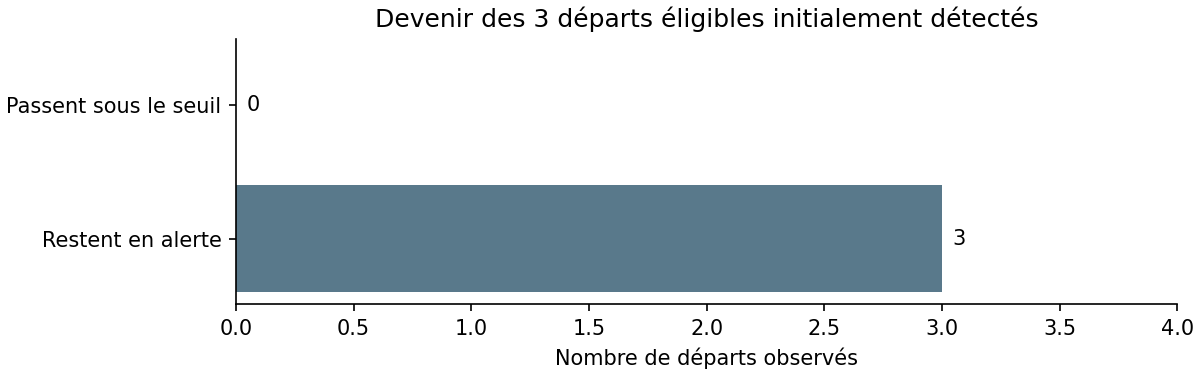

**Phrase pour la slide**

Dans le scénario où les salariés sans formation en suivent une, 0 des 3 départs observés chez les salariés éligibles et initialement détectés passent sous le seuil d’alerte (0,0 %, IC de Wilson à 95 % [0,0 % ; 56,1 %]).

In [3]:

from io import BytesIO
from statistics import NormalDist

from IPython.display import Image, Markdown, display

departs_eligibles = eligibles & y_test.eq(1)
initialement_detectes = departs_eligibles & prediction_avant
Y = int(initialement_detectes.sum())
X = int((initialement_detectes & ~prediction_apres).sum())
restent_en_alerte = int((initialement_detectes & prediction_apres).sum())
assert X + restent_en_alerte == Y

def format_fr(nombre, decimales=1):
    return f'{nombre:.{decimales}f}'.replace('.', ',')

pourcentage = 'Indéfini (Y = 0)'
intervalle = 'Indéfini (Y = 0)'
if Y:
    proportion = X / Y
    z = NormalDist().inv_cdf(.975)
    facteur = 1 + z**2 / Y
    centre = (proportion + z**2 / (2 * Y)) / facteur
    demi_largeur = z * np.sqrt(proportion * (1 - proportion) / Y + z**2 / (4 * Y**2)) / facteur
    pourcentage = f'{format_fr(100 * proportion)} %'
    intervalle = f'[{format_fr(100 * max(0, centre - demi_largeur))} % ; {format_fr(100 * min(1, centre + demi_largeur))} %]'

n_eligibles = int(eligibles.sum())
alertes_avant = int((eligibles & prediction_avant).sum())
alertes_apres = int((eligibles & prediction_apres).sum())
baisse_pp = 100 * (score_avant.loc[eligibles] - score_apres.loc[eligibles]).mean()
synthese = pd.DataFrame([
    ('Salariés éligibles', n_eligibles),
    ('Départs observés parmi les éligibles', int(departs_eligibles.sum())),
    ('Alertes avant parmi tous les éligibles', alertes_avant),
    ('Alertes après parmi tous les éligibles', alertes_apres),
    ('Baisse moyenne du score (points de pourcentage)', format_fr(baisse_pp, 2)),
    ('Départs éligibles initialement détectés (Y)', Y),
    ('Passent sous le seuil (X)', X),
    ('Restent en alerte (Y−X)', restent_en_alerte),
    ('Part passant sous le seuil (X/Y)', pourcentage),
    ('IC de Wilson à 95 %', intervalle),
], columns=['Indicateur', 'Résultat'])
display(synthese)
if 0 < Y < 30:
    print(f'Petit dénominateur (Y = {Y}, repère de lecture < 30).')

fig, ax = plt.subplots(figsize=(8, 2.5), layout='constrained')
barres = ax.barh(['Passent sous le seuil', 'Restent en alerte'], [X, restent_en_alerte],
                 color=['#00776c', '#59798b'])
ax.bar_label(barres, padding=5)
ax.set(xlim=(0, Y + max(1, .1 * Y)), xlabel='Nombre de départs observés',
       title=f'Devenir des {Y} départs éligibles initialement détectés')
ax.invert_yaxis()
ax.spines[['top', 'right']].set_visible(False)
with BytesIO() as image:
    fig.savefig(image, format='png', dpi=150)
    display(Image(data=image.getvalue()))
plt.close(fig)

if Y:
    phrase = (f'Dans le scénario {libelle}, {X} des {Y} départs observés chez les salariés '
              f'éligibles et initialement détectés passent sous le seuil d’alerte '
              f'({pourcentage}, IC de Wilson à 95 % {intervalle}).')
else:
    phrase = (f'Dans le scénario {libelle}, aucun départ observé chez les salariés éligibles '
              'n’était initialement détecté. La part passant sous le seuil est indéfinie.')
display(Markdown(f'**Phrase pour la slide**\n\n{phrase}'))
print(synthese.to_string(index=False))
